In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

In [20]:
CSV_PATH = "csv/dataset_final.csv"  # <-- ajusta a tu ruta real
df = pd.read_csv(CSV_PATH)
 
print(f"Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas")

Dataset cargado: 29991 filas, 59 columnas


In [21]:
cols_comp = [c for c in df.columns if c.startswith("comp_")]
print(f"\nColumnas comp_ a eliminar ({len(cols_comp)}):")
print(cols_comp)
 
df = df.drop(columns=cols_comp)
 
print(f"\nDataset resultante: {df.shape[0]} filas, {df.shape[1]} columnas")
print("\nColumnas restantes:")
print(df.columns.tolist())

df.to_csv("csv/dataset_final_orig.csv", index=False)

df.info()
 


Columnas comp_ a eliminar (26):
['comp_media_lum', 'comp_var_lum', 'comp_rango', 'comp_std', 'comp_michelson', 'comp_hf', 'comp_lf', 'comp_hlfr', 'comp_edges_s1', 'comp_edges_s2', 'comp_edges_s3', 'comp_grad_mean', 'comp_grad_std', 'comp_glcm_contrast', 'comp_glcm_hom', 'comp_glcm_energy', 'comp_glcm_corr', 'comp_entropia_shannon', 'comp_entropia_espectral', 'comp_entropia_gradiente', 'comp_entropia_glcm', 'comp_sat_mean', 'comp_sat_var', 'comp_hue_var', 'comp_megapixeles', 'comp_aspect_ratio']

Dataset resultante: 29991 filas, 33 columnas

Columnas restantes:
['img_original', 'img_recodificada', 'metodo', 'formato_salida', 'calidad', 'orig_media_lum', 'orig_var_lum', 'orig_rango', 'orig_std', 'orig_michelson', 'orig_hf', 'orig_lf', 'orig_hlfr', 'orig_edges_s1', 'orig_edges_s2', 'orig_edges_s3', 'orig_grad_mean', 'orig_grad_std', 'orig_glcm_contrast', 'orig_glcm_hom', 'orig_glcm_energy', 'orig_glcm_corr', 'orig_entropia_shannon', 'orig_entropia_espectral', 'orig_entropia_gradiente', '

In [22]:
df = pd.read_csv("csv/dataset_final_orig.csv")
print(f"Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas")

Dataset cargado: 29991 filas, 33 columnas


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29991 entries, 0 to 29990
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   img_original             29991 non-null  object 
 1   img_recodificada         29991 non-null  object 
 2   metodo                   29991 non-null  object 
 3   formato_salida           29991 non-null  object 
 4   calidad                  29991 non-null  int64  
 5   orig_media_lum           29991 non-null  float64
 6   orig_var_lum             29991 non-null  float64
 7   orig_rango               29991 non-null  float64
 8   orig_std                 29991 non-null  float64
 9   orig_michelson           29991 non-null  float64
 10  orig_hf                  29991 non-null  float64
 11  orig_lf                  29991 non-null  float64
 12  orig_hlfr                29991 non-null  float64
 13  orig_edges_s1            29991 non-null  float64
 14  orig_edges_s2         

# Análisis descriptivo de variables numéricas y variable objetivo

# 1. ESTADISTICAS DESCRIPTIVAS GENERALES

In [27]:
OUT_DIR = "csv/eda_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
 
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = ["metodo", "formato_salida", "formato_entrada"]
target = "lpips"
features_orig = [c for c in num_cols if c.startswith("orig_")]
 
print(f"Dataset: {df.shape[0]} filas, {df.shape[1]} columnas")
print(f"Numericas: {len(num_cols)} | Categoricas: {cat_cols} | Target: {target}")
print(f"Features orig_: {len(features_orig)}")

Dataset: 29991 filas, 33 columnas
Numericas: 28 | Categoricas: ['metodo', 'formato_salida', 'formato_entrada'] | Target: lpips
Features orig_: 26


# CELDA 1 — ESTADISTICAS DESCRIPTIVAS

In [28]:
print("=" * 70)
print("1. ESTADISTICAS DESCRIPTIVAS (numericas)")
print("=" * 70)
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurtosis()
print(desc.to_string())
desc.to_csv(f"{OUT_DIR}/estadisticas_descriptivas.csv")
 
print("\n" + "=" * 70)
print("1b. FRECUENCIAS DE VARIABLES CATEGORICAS")
print("=" * 70)
for col in cat_cols + ["calidad"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().to_string())

1. ESTADISTICAS DESCRIPTIVAS (numericas)
                           count           mean            std           min         25%            50%             75%             max       skew     kurtosis
calidad                  29991.0      50.265413      28.257077  1.000000e+01   30.000000      50.000000       70.000000       90.000000  -0.018296    -1.301098
orig_media_lum           29991.0       0.469530       0.158674  0.000000e+00    0.375627       0.453575        0.549925        1.000000   0.382894     0.723681
orig_var_lum             29991.0       0.055864       0.030030  0.000000e+00    0.034811       0.051589        0.072124        0.230775   0.950310     1.578090
orig_rango               29991.0  579508.800851  484866.836302  0.000000e+00  133.315558  991055.686275  1000000.000000  1000000.000000  -0.337258    -1.865887
orig_std                 29991.0       0.227177       0.065232  0.000000e+00    0.186576       0.227131        0.268560        0.480390  -0.090866     0.558323

# CELDA 2 — VALORES NULOS

2. VALORES NULOS
orig_hue_var               396
orig_entropia_espectral      4
lpips                        2


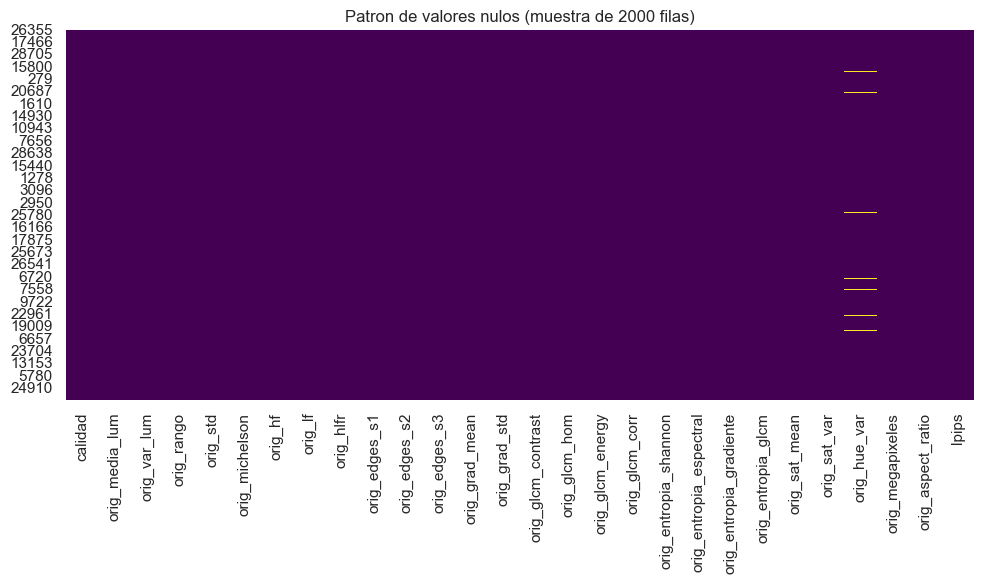

Guardado: csv/eda_outputs/heatmap_patron_nulos.png

Nulos de 'orig_hue_var' por metodo:
metodo
ffmpeg         135
imagemagick    134
pillow         127
Nulos de 'orig_hue_var' por formato_salida:
formato_salida
webp    236
png     140
jpg      20
Nulos de 'orig_hue_var' por formato_entrada:
formato_entrada
jpg     283
png     106
webp      7
Nulos de 'orig_hue_var' por calidad:
calidad
10    81
30    77
50    68
70    84
90    86

Nulos de 'orig_entropia_espectral' por metodo:
metodo
imagemagick    2
ffmpeg         1
pillow         1
Nulos de 'orig_entropia_espectral' por formato_salida:
formato_salida
jpg    4
Nulos de 'orig_entropia_espectral' por formato_entrada:
formato_entrada
png    4
Nulos de 'orig_entropia_espectral' por calidad:
calidad
10    1
30    1
50    1
90    1

Nulos de 'lpips' por metodo:
metodo
imagemagick    2
Nulos de 'lpips' por formato_salida:
formato_salida
jpg    2
Nulos de 'lpips' por formato_entrada:
formato_entrada
png    2
Nulos de 'lpips' por calidad:
cali

In [30]:
print("=" * 70)
print("2. VALORES NULOS")
print("=" * 70)
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(nulos.to_string() if len(nulos) else "Sin nulos")
 
plt.figure(figsize=(10, 6))
muestra = df.sample(min(2000, len(df)), random_state=42)
sns.heatmap(muestra[num_cols].isna(), cbar=False, cmap="viridis")
plt.title("Patron de valores nulos (muestra de 2000 filas)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_patron_nulos.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_patron_nulos.png")
 
for col in nulos.index:
    print(f"\nNulos de '{col}' por metodo:")
    mask = df[col].isna()
    print(df.loc[mask, "metodo"].value_counts().to_string())
    print(f"Nulos de '{col}' por formato_salida:")
    print(df.loc[mask, "formato_salida"].value_counts().to_string())
    print(f"Nulos de '{col}' por formato_entrada:")
    print(df.loc[mask, "formato_entrada"].value_counts().to_string())
    print(f"Nulos de '{col}' por calidad:")
    print(df.loc[mask, "calidad"].value_counts().sort_index().to_string())

# CELDA 3 — DISTRIBUCIONES UNIVARIADAS (todas las features + target)

3. DISTRIBUCIONES UNIVARIADAS


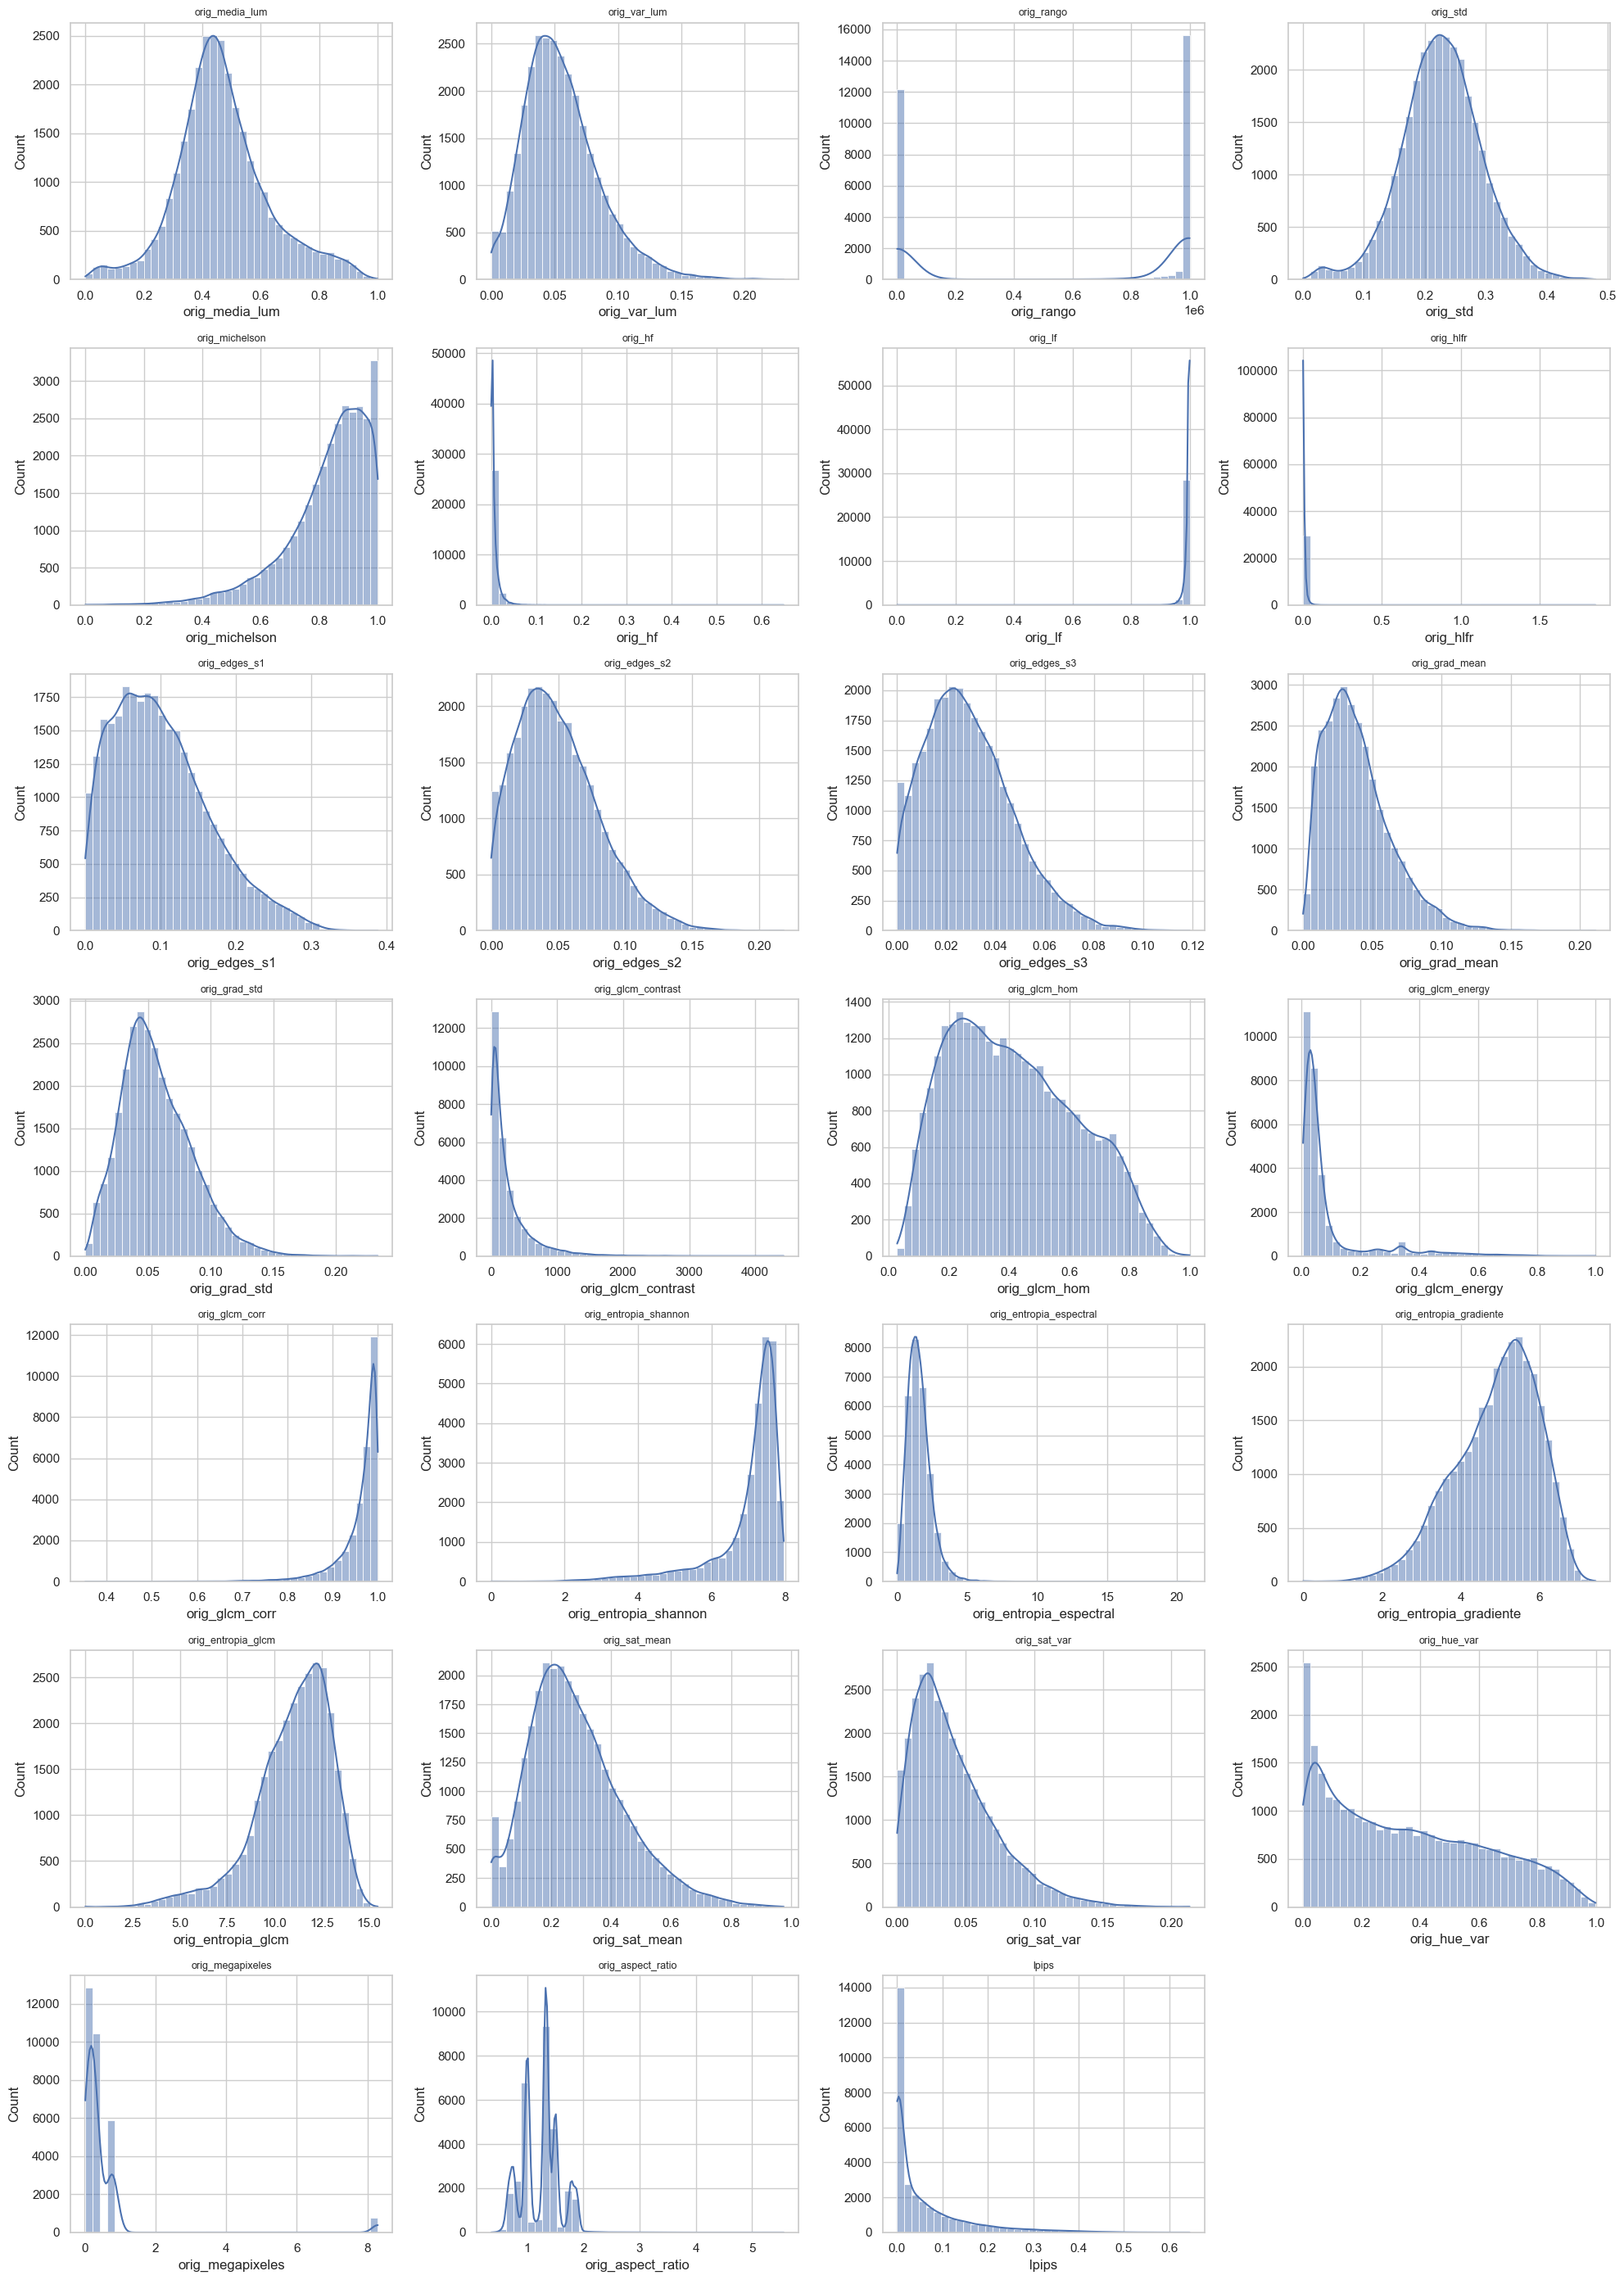

Guardado: csv/eda_outputs/distribuciones_univariadas.png


In [31]:
print("=" * 70)
print("3. DISTRIBUCIONES UNIVARIADAS")
print("=" * 70)
 
n_cols_grid = 4
cols_a_graficar = features_orig + [target]
n_rows_grid = int(np.ceil(len(cols_a_graficar) / n_cols_grid))
 
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(20, 4 * n_rows_grid))
axes = axes.ravel()
 
for i, col in enumerate(cols_a_graficar):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=40)
    axes[i].set_title(col, fontsize=9)
 
for j in range(len(cols_a_graficar), len(axes)):
    fig.delaxes(axes[j])
 
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/distribuciones_univariadas.png", dpi=130)
plt.show()
print(f"Guardado: {OUT_DIR}/distribuciones_univariadas.png")

# CELDA 4 — DISTRIBUCION DETALLADA DEL TARGET (lpips)

4. DISTRIBUCION DE LPIPS (target)


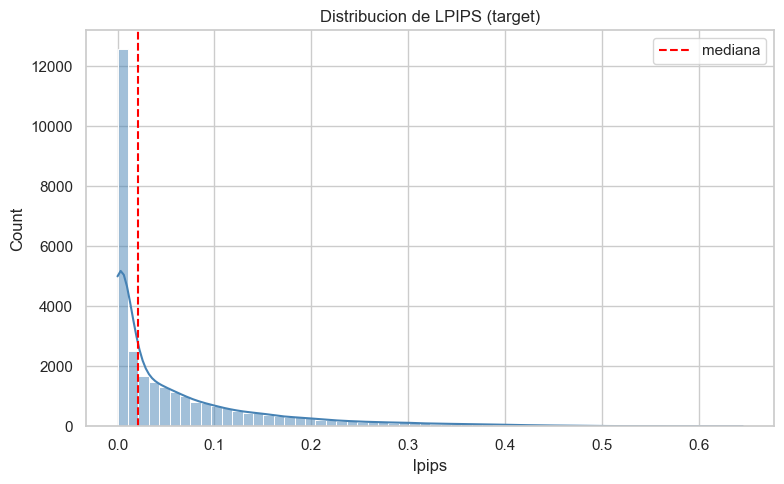

Guardado: csv/eda_outputs/distribucion_lpips.png
count    29989.000000
mean         0.061067
std          0.089035
min          0.000000
50%          0.021126
90%          0.182943
95%          0.258648
99%          0.394983
max          0.645018


In [32]:
print("=" * 70)
print("4. DISTRIBUCION DE LPIPS (target)")
print("=" * 70)
plt.figure(figsize=(8, 5))
sns.histplot(df[target].dropna(), kde=True, bins=60, color="steelblue")
plt.axvline(df[target].median(), color="red", linestyle="--", label="mediana")
plt.title("Distribucion de LPIPS (target)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/distribucion_lpips.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/distribucion_lpips.png")
print(df[target].describe(percentiles=[.5, .9, .95, .99]).to_string())

# CELDA 5 — DISTRIBUCION DE VARIABLES CATEGORICAS

5. DISTRIBUCION DE CATEGORICAS


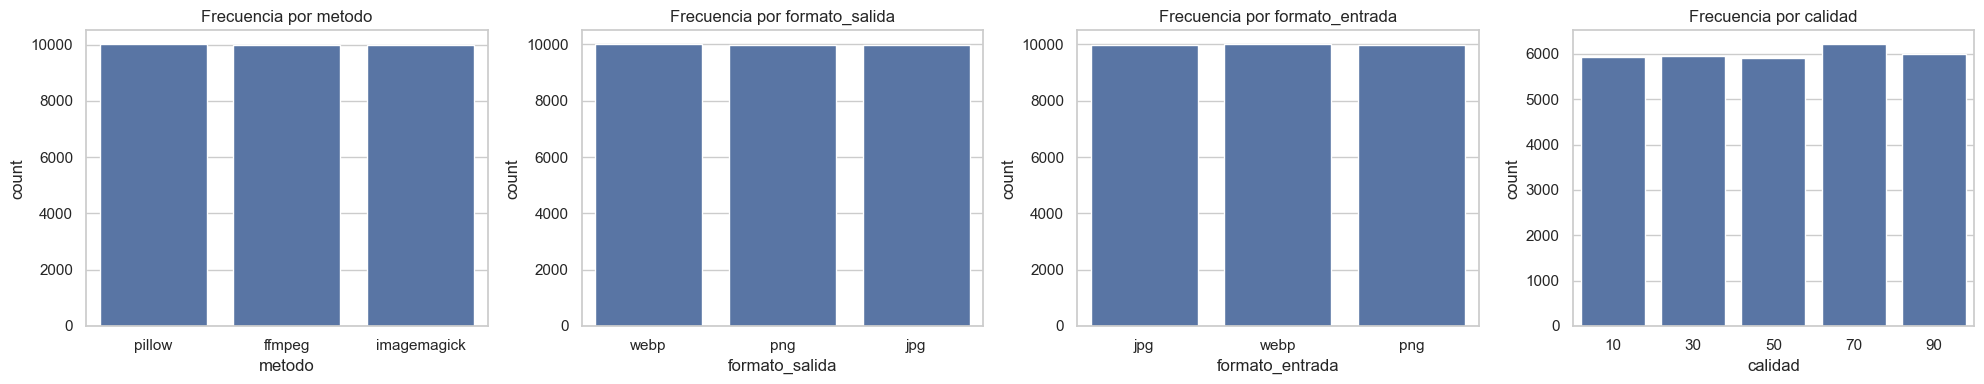

Guardado: csv/eda_outputs/distribucion_categoricas.png


In [33]:
print("=" * 70)
print("5. DISTRIBUCION DE CATEGORICAS")
print("=" * 70)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.countplot(data=df, x="metodo", ax=axes[0])
axes[0].set_title("Frecuencia por metodo")
sns.countplot(data=df, x="formato_salida", ax=axes[1])
axes[1].set_title("Frecuencia por formato_salida")
sns.countplot(data=df, x="formato_entrada", ax=axes[2])
axes[2].set_title("Frecuencia por formato_entrada")
sns.countplot(data=df, x="calidad", ax=axes[3])
axes[3].set_title("Frecuencia por calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/distribucion_categoricas.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/distribucion_categoricas.png")

# CELDA 6 — ANALISIS COMBINADO: lpips vs metodo / formato / calidad

6. LPIPS SEGUN METODO / FORMATO / CALIDAD


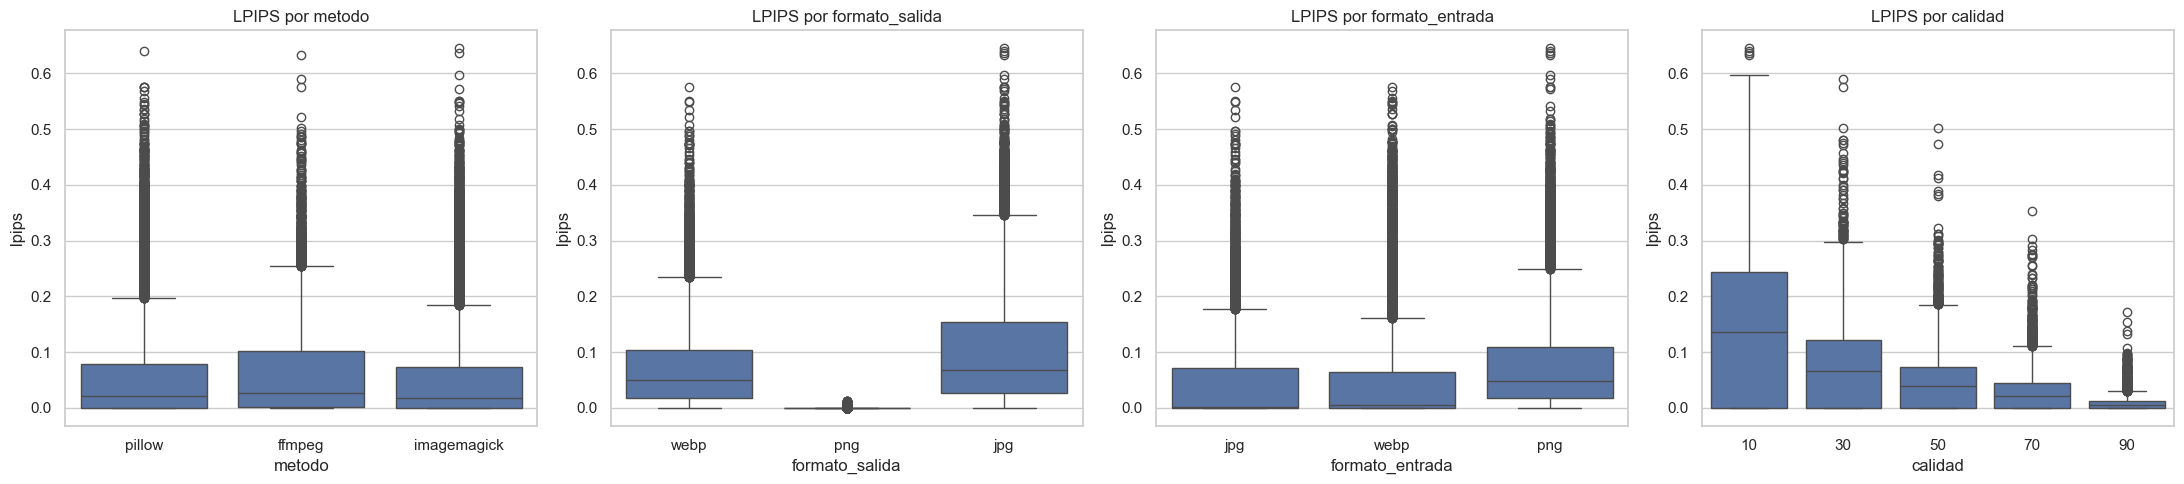

Guardado: csv/eda_outputs/lpips_por_categoria.png

LPIPS promedio por combinacion metodo x calidad:
calidad            10        30        50        70        90
metodo                                                       
ffmpeg       0.126566  0.088834  0.062122  0.039471  0.012918
imagemagick  0.152105  0.066790  0.042418  0.024371  0.006590
pillow       0.156796  0.068418  0.041879  0.024851  0.007341


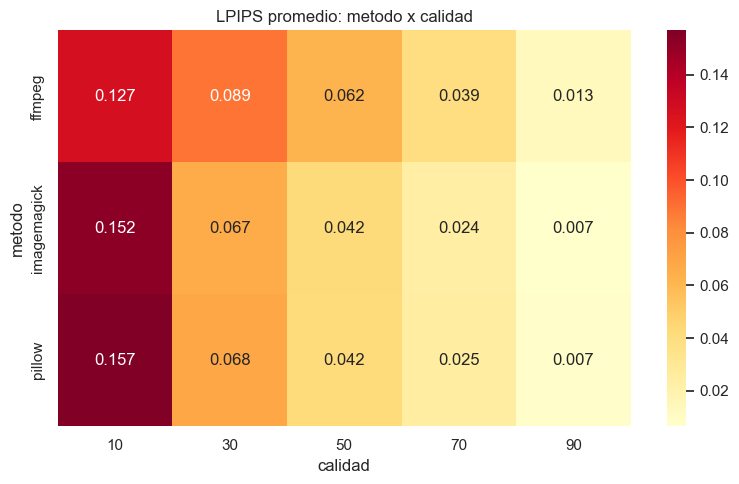

Guardado: csv/eda_outputs/heatmap_lpips_metodo_calidad.png

LPIPS promedio por combinacion formato_salida x calidad:
calidad               10        30        50        70        90
formato_salida                                                  
jpg             0.270699  0.129895  0.080013  0.047025  0.015166
png             0.000417  0.000483  0.000507  0.000466  0.000492
webp            0.165984  0.094342  0.064324  0.042662  0.011093


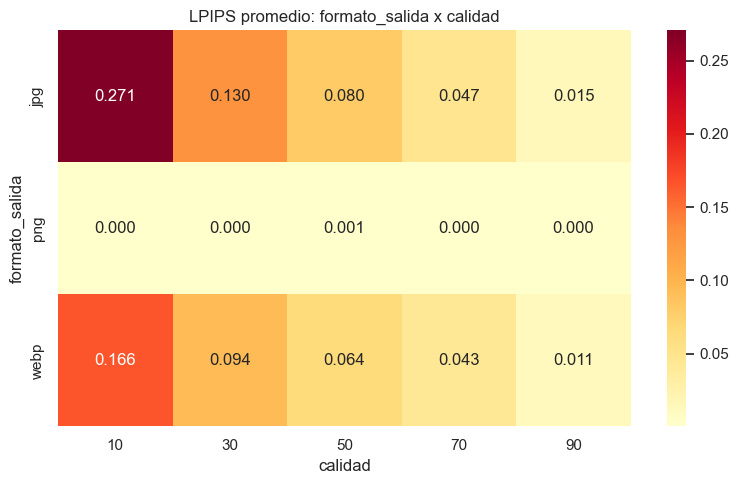

Guardado: csv/eda_outputs/heatmap_lpips_formato_calidad.png

LPIPS promedio por combinacion formato_entrada x formato_salida:
formato_salida        jpg       png      webp
formato_entrada                              
jpg                   NaN  0.000052  0.094762
png              0.109037       NaN  0.055708
webp             0.106035  0.000894       NaN


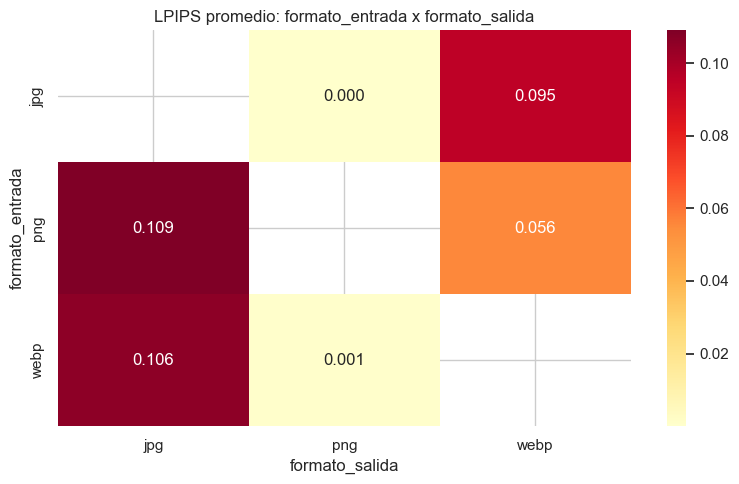

Guardado: csv/eda_outputs/heatmap_lpips_entrada_salida.png


In [34]:
print("=" * 70)
print("6. LPIPS SEGUN METODO / FORMATO / CALIDAD")
print("=" * 70)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
sns.boxplot(data=df, x="metodo", y=target, ax=axes[0])
axes[0].set_title("LPIPS por metodo")
sns.boxplot(data=df, x="formato_salida", y=target, ax=axes[1])
axes[1].set_title("LPIPS por formato_salida")
sns.boxplot(data=df, x="formato_entrada", y=target, ax=axes[2])
axes[2].set_title("LPIPS por formato_entrada")
sns.boxplot(data=df, x="calidad", y=target, ax=axes[3])
axes[3].set_title("LPIPS por calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/lpips_por_categoria.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/lpips_por_categoria.png")
 
print("\nLPIPS promedio por combinacion metodo x calidad:")
pivot = df.pivot_table(values=target, index="metodo", columns="calidad", aggfunc="mean")
print(pivot.to_string())
 
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("LPIPS promedio: metodo x calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_lpips_metodo_calidad.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_lpips_metodo_calidad.png")
 
print("\nLPIPS promedio por combinacion formato_salida x calidad:")
pivot2 = df.pivot_table(values=target, index="formato_salida", columns="calidad", aggfunc="mean")
print(pivot2.to_string())
 
plt.figure(figsize=(8, 5))
sns.heatmap(pivot2, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("LPIPS promedio: formato_salida x calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_lpips_formato_calidad.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_lpips_formato_calidad.png")
 
print("\nLPIPS promedio por combinacion formato_entrada x formato_salida:")
pivot3 = df.pivot_table(values=target, index="formato_entrada", columns="formato_salida", aggfunc="mean")
print(pivot3.to_string())
 
plt.figure(figsize=(8, 5))
sns.heatmap(pivot3, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("LPIPS promedio: formato_entrada x formato_salida")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_lpips_entrada_salida.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_lpips_entrada_salida.png")
 

# CELDA 7 — MATRIZ DE CORRELACION COMPLETA

7. MATRIZ DE CORRELACION


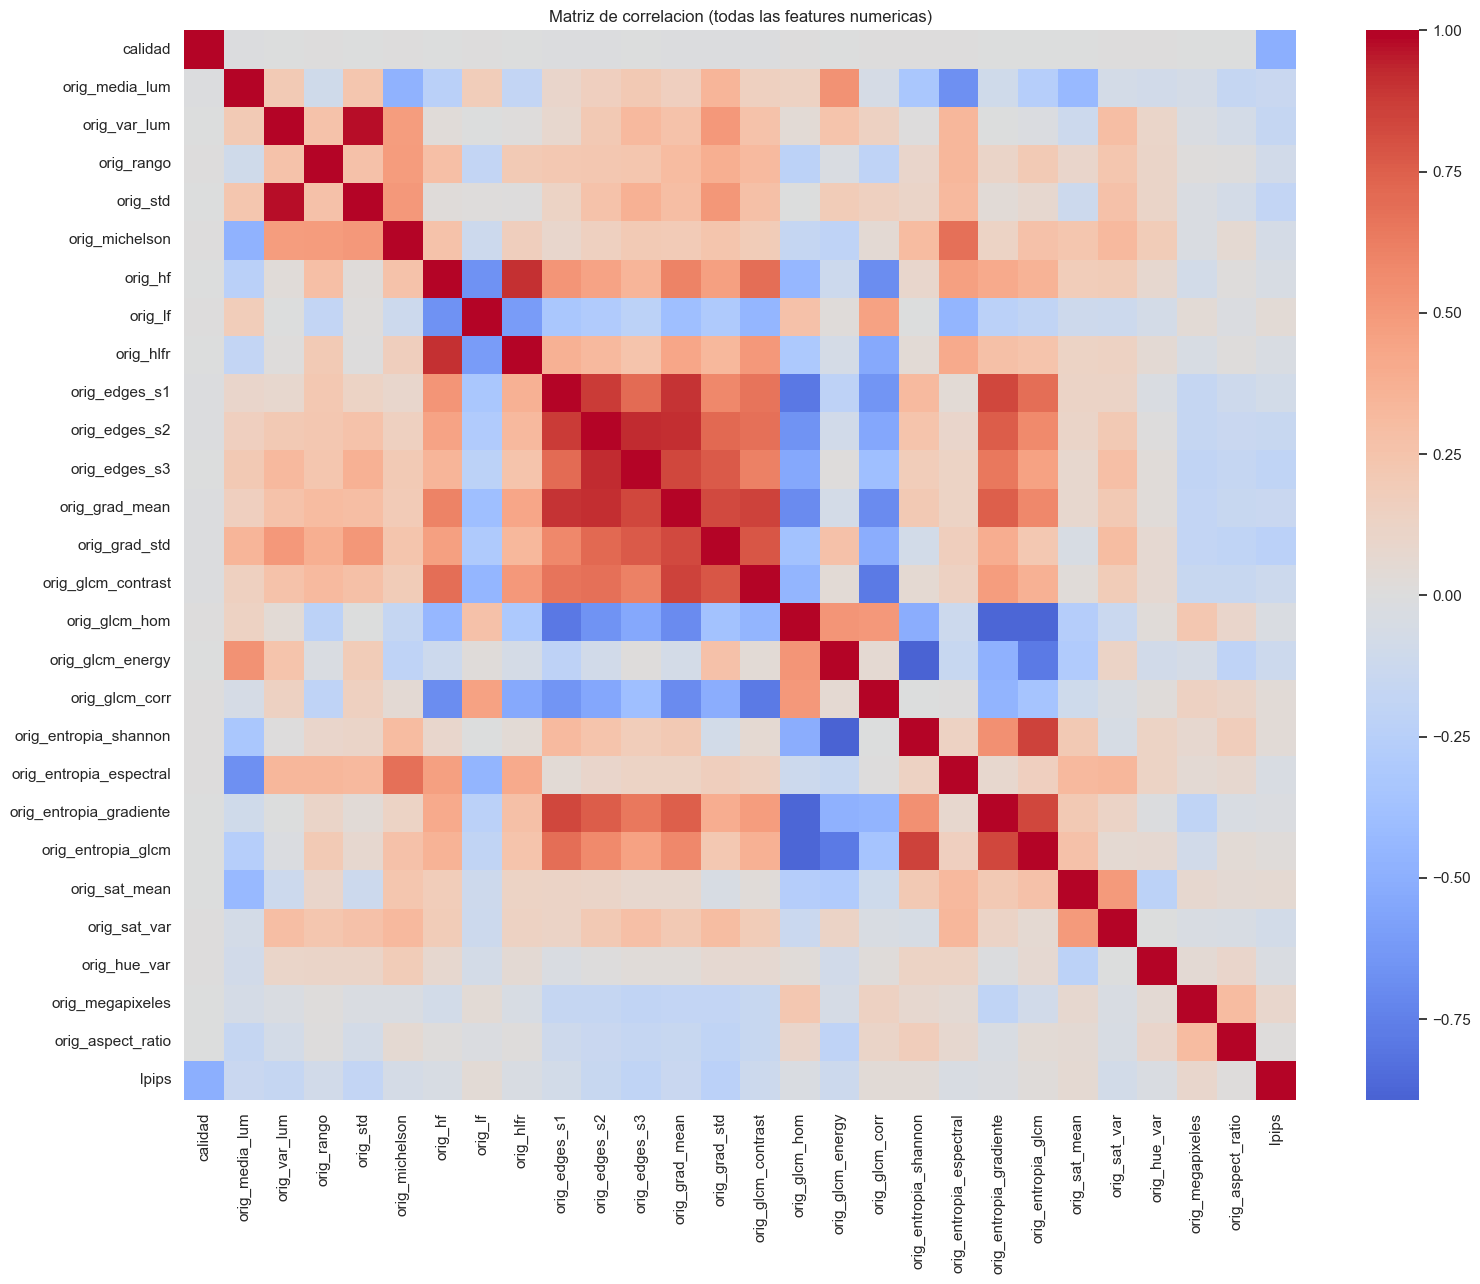

Guardado: csv/eda_outputs/heatmap_correlacion_completa.png


In [35]:
print("=" * 70)
print("7. MATRIZ DE CORRELACION")
print("=" * 70)
corr = df[num_cols].corr()
 
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Matriz de correlacion (todas las features numericas)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_correlacion_completa.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_correlacion_completa.png")

# CELDA 8 — CORRELACION DE CADA FEATURE CON EL TARGET

8. CORRELACION DE CADA FEATURE CON LPIPS
calidad                   -0.503457
orig_grad_std             -0.227866
orig_edges_s3             -0.198184
orig_std                  -0.179057
orig_var_lum              -0.161594
orig_edges_s2             -0.152196
orig_media_lum            -0.142868
orig_grad_mean            -0.139484
orig_glcm_contrast        -0.122027
orig_glcm_energy          -0.120695
orig_rango                -0.091151
orig_megapixeles           0.086310
orig_edges_s1             -0.083959
orig_sat_var              -0.081574
orig_michelson            -0.066065
orig_sat_mean              0.060382
orig_hf                   -0.048347
orig_lf                    0.041718
orig_entropia_shannon      0.037284
orig_hlfr                 -0.036829
orig_entropia_espectral   -0.035974
orig_glcm_corr             0.031770
orig_glcm_hom             -0.027101
orig_hue_var              -0.024894
orig_entropia_gradiente   -0.018392
orig_entropia_glcm         0.017523
orig_aspect_ratio      

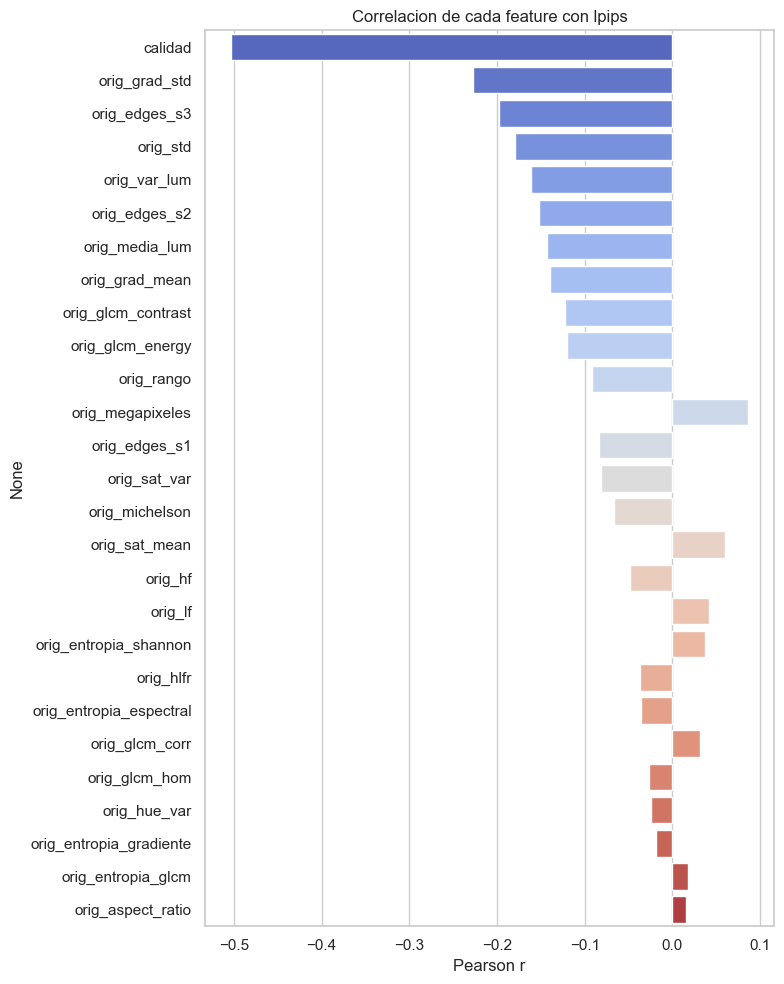

Guardado: csv/eda_outputs/barplot_correlacion_target.png


In [36]:
print("=" * 70)
print("8. CORRELACION DE CADA FEATURE CON LPIPS")
print("=" * 70)
corr_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
print(corr_target.to_string())
corr_target.to_csv(f"{OUT_DIR}/correlacion_con_target.csv")
 
plt.figure(figsize=(8, 10))
sns.barplot(x=corr_target.values, y=corr_target.index, hue=corr_target.index,
            palette="coolwarm", legend=False)
plt.title(f"Correlacion de cada feature con {target}")
plt.xlabel("Pearson r")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/barplot_correlacion_target.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/barplot_correlacion_target.png")

# CELDA 9 — MULTICOLINEALIDAD ENTRE FEATURES

In [37]:
print("=" * 70)
print("9. PARES DE FEATURES CON MULTICOLINEALIDAD ALTA (|r| > 0.9)")
print("=" * 70)
cols_feat = [c for c in num_cols if c != target]
alta_corr = []
for i in range(len(cols_feat)):
    for j in range(i + 1, len(cols_feat)):
        r = corr.loc[cols_feat[i], cols_feat[j]]
        if abs(r) > 0.9:
            alta_corr.append((cols_feat[i], cols_feat[j], r))
 
if alta_corr:
    for a, b, r in sorted(alta_corr, key=lambda x: -abs(x[2])):
        print(f"  {a} <-> {b}: r={r:.4f}")
else:
    print("No se encontraron pares con |r| > 0.9")
print(f"\nTotal de pares con alta multicolinealidad: {len(alta_corr)}")

9. PARES DE FEATURES CON MULTICOLINEALIDAD ALTA (|r| > 0.9)
  orig_var_lum <-> orig_std: r=0.9741
  orig_edges_s2 <-> orig_edges_s3: r=0.9217
  orig_edges_s2 <-> orig_grad_mean: r=0.9158
  orig_hf <-> orig_hlfr: r=0.9055
  orig_edges_s1 <-> orig_grad_mean: r=0.9004

Total de pares con alta multicolinealidad: 5


# CELDA 10 — DETECCION DE OUTLIERS (metodo IQR)

10. DETECCION DE OUTLIERS (metodo IQR)
                feature  n_outliers    pct
       orig_megapixeles        6674 22.253
       orig_glcm_energy        4328 14.431
  orig_entropia_shannon        3151 10.506
              orig_hlfr        2575  8.586
                orig_lf        2525  8.419
                orig_hf        2524  8.416
     orig_glcm_contrast        2333  7.779
                  lpips        2238  7.462
         orig_glcm_corr        2237  7.459
         orig_media_lum        1642  5.475
         orig_michelson        1155  3.851
     orig_entropia_glcm         959  3.198
           orig_sat_var         798  2.661
orig_entropia_espectral         728  2.427
           orig_var_lum         719  2.397
         orig_grad_mean         669  2.231
               orig_std         650  2.167
          orig_sat_mean         605  2.017
          orig_grad_std         452  1.507
          orig_edges_s2         367  1.224
          orig_edges_s3         362  1.207
          orig_

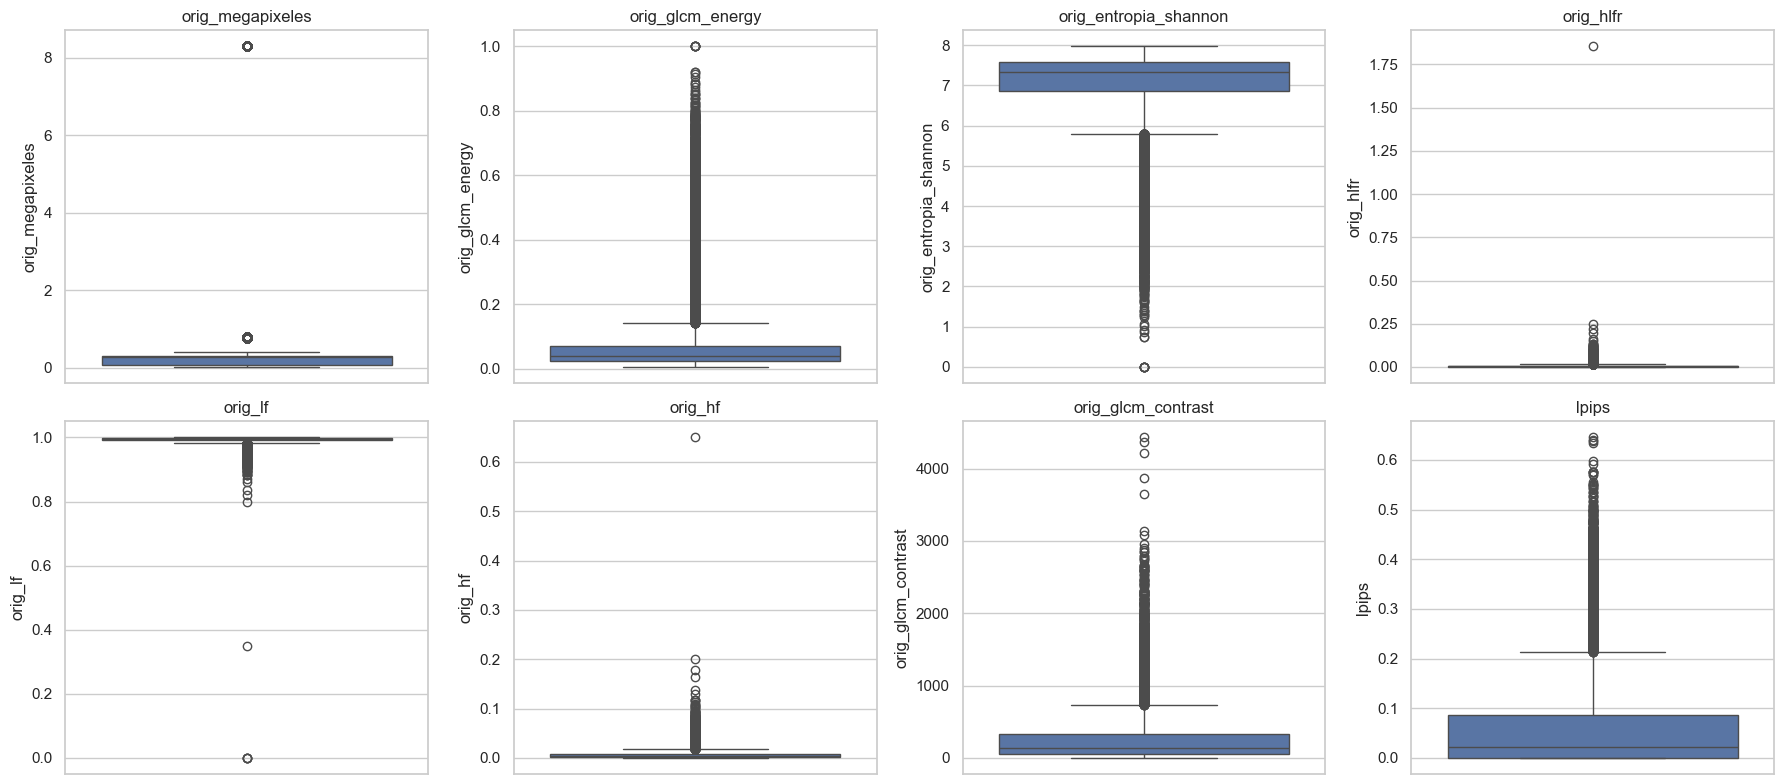


Guardado: csv/eda_outputs/boxplots_top_outliers.png


In [38]:
print("=" * 70)
print("10. DETECCION DE OUTLIERS (metodo IQR)")
print("=" * 70)
outlier_summary = []
for col in features_orig + [target]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    outlier_summary.append({"feature": col, "n_outliers": n_out,
                             "pct": round(n_out / len(df) * 100, 3)})
 
outlier_df = pd.DataFrame(outlier_summary).sort_values("pct", ascending=False)
print(outlier_df.to_string(index=False))
outlier_df.to_csv(f"{OUT_DIR}/resumen_outliers_iqr.csv", index=False)
 
top_outlier_feats = outlier_df.head(8)["feature"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), top_outlier_feats):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/boxplots_top_outliers.png", dpi=150)
plt.show()
print(f"\nGuardado: {OUT_DIR}/boxplots_top_outliers.png")
 

# CELDA 11 — DISPERSION: FEATURES MAS CORRELACIONADAS CON EL TARGET

11. RELACION DE LAS FEATURES MAS CORRELACIONADAS CON LPIPS


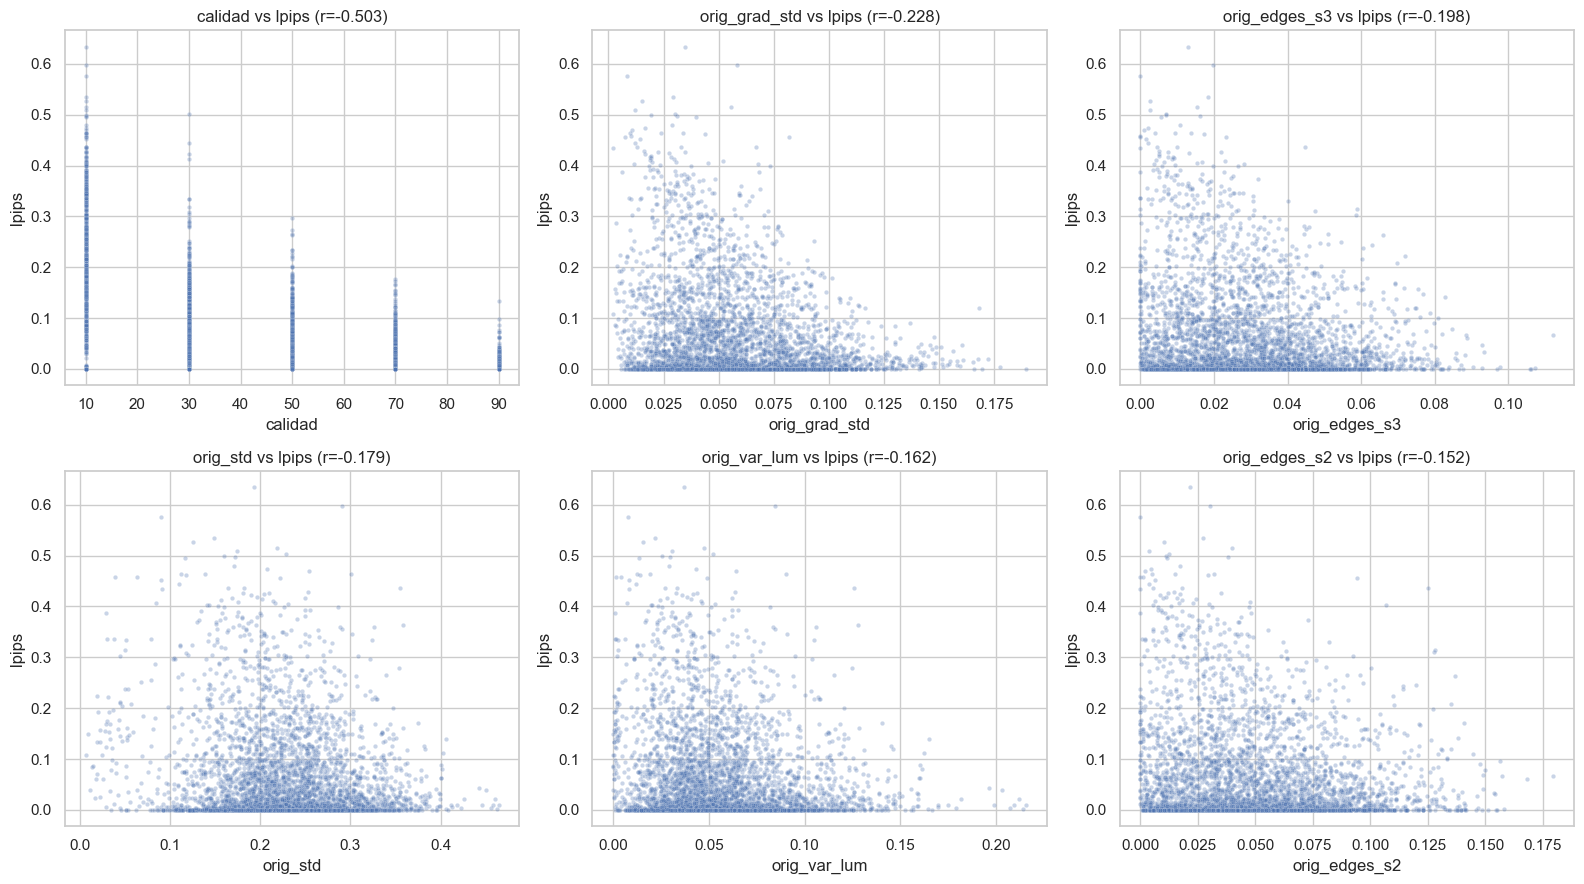

Guardado: csv/eda_outputs/scatter_top_features_vs_target.png


In [39]:
print("=" * 70)
print("11. RELACION DE LAS FEATURES MAS CORRELACIONADAS CON LPIPS")
print("=" * 70)
top_feats = corr_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), top_feats):
    muestra_scatter = df.sample(min(4000, len(df)), random_state=42)
    sns.scatterplot(data=muestra_scatter, x=col, y=target, alpha=0.3, s=10, ax=ax)
    ax.set_title(f"{col} vs {target} (r={corr_target[col]:.3f})")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/scatter_top_features_vs_target.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/scatter_top_features_vs_target.png")

# CELDA 12 — RESUMEN FINAL DEL EDA

In [40]:
print("=" * 70)
print("RESUMEN FINAL DEL EDA")
print("=" * 70)
print(f"Filas: {len(df)} | Columnas: {df.shape[1]}")
print(f"Nulos totales: {df.isna().sum().sum()}")
print(f"Features con multicolinealidad alta (|r|>0.9): {len(alta_corr)} pares")
print(f"Feature mas correlacionada con {target}: "
      f"{corr_target.index[0]} (r={corr_target.iloc[0]:.4f})")
print(f"\nTodas las figuras y tablas se guardaron en la carpeta: {OUT_DIR}/")

RESUMEN FINAL DEL EDA
Filas: 29991 | Columnas: 33
Nulos totales: 402
Features con multicolinealidad alta (|r|>0.9): 5 pares
Feature mas correlacionada con lpips: calidad (r=-0.5035)

Todas las figuras y tablas se guardaron en la carpeta: csv/eda_outputs/
